# 99장 · 시간 초과의 재시도와 중단 조건

시간 초과 뒤 다시 시도할 수 있어도 같은 요청을 끝없이 보낼 수는 없습니다. 실행 기록에서 재시도 횟수와 중단 사유를 읽습니다.

검색 도구가 잠시 늦으면 사용자는 다시 눌러야 할지 기다려야 할지 모릅니다. 일정을 묻고 근거가 없었던 답은 정상 종료지만, 도구 시간 초과는 작업이 끝나지 않은 상태입니다. 두 경우의 안내와 기록을 따로 설계합니다.

실행을 확인한 커널은 Python 3.12.15입니다.

Python 3 커널을 선택하고 위에서부터 실행하세요. 팀별 변형을 시도한 뒤 해당 셀 아래에서 예시를 펼쳐 비교할 수 있습니다.


## 일시 오류 후 재시도 기록

복구 기록 F99-recover　Q01의 첫 시도에서 가상 도구가 TimeoutError를 냈습니다. 작업을 paused에 두었다가 원래 요청 ID로 두 번째 시도를 해서 마쳤습니다. 여기서 시간 초과는 교육 예제에서 의도적으로 일으킨 실패입니다.


### 셀 01 · 재시도 이벤트 순서

제공 실행 기록에서 F99-recover의 사건만 꺼낸 자료입니다. attempts를 무조건 1로 다시 시작하면 원인을 놓칩니다.

F99-recover는 한 요청을 두 번 시도한 예입니다. 첫 시도는 TimeoutError 뒤에 멈추고 두 번째 시도에서 마칩니다. 팀 기록에서는 두 줄에 같은 요청 ID와 서로 다른 시도 번호를 적으세요. 이 셀의 events만으로 ID가 일치했는지까지 확인할 수는 없습니다.


In [1]:
events = [{'event': 'attempt', 'attempt': 1},
 {'event': 'paused', 'attempt': 1, 'error_type': 'TimeoutError'},
 {'event': 'retry', 'attempt': 1},
 {'event': 'attempt', 'attempt': 2},
 {'event': 'completed', 'attempt': 2, 'error_type': ''}]
for event in events:
    print(event["attempt"], event["event"])

1 attempt
1 paused
1 retry
2 attempt
2 completed


시도 1에는 attempt·paused·retry가, 시도 2에는 attempt·completed가 보입니다. retry 행의 1은 첫 실패를 마치고 재시도를 결정한 위치입니다. 실제 두 번째 호출은 다음 attempt에서 시작합니다.


## 반복 실패의 종료 사유

실행 상한 예시　최대 시도 2회 / 둘째 시도에서도 시간 초과 / 최종 사건 attempt_limit / 사용자 안내 시안 “지금은 검색을 마치지 못했습니다. 잠시 뒤 다시 요청해 주세요.” 실패를 no_evidence로 보고하면 사용자는 원문 자료가 없다고 잘못 이해합니다. 결제나 예약이 있는 팀은 재시도가 같은 동작을 두 번 수행하지 않는지도 별도로 설계해야 합니다.

<!-- lesson-visual visual-limit -->
**두 번째 타임아웃 뒤에는 몇 번 더 시도할까요?**

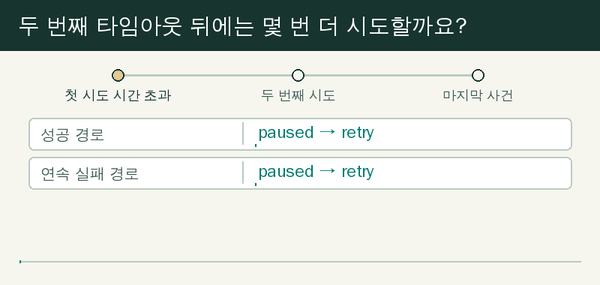

성공한 실행과 두 번 모두 실패한 실행을 나란히 읽습니다. 상한에 닿으면 마지막 사건은 attempt_limit이고 세 번째 호출은 없습니다.
<!-- /lesson-visual visual-limit -->


### 과제 02 · 선택 연습 · 종료 사유 기록

F99-limit의 마지막 사건을 읽어 화면 담당자에게 횟수와 원인을 전하세요.


In [2]:
final_event = {'event': 'attempt_limit', 'attempt': 2, 'error_type': 'TimeoutError'}
# 마지막 사건·횟수·오류명을 표시하세요.

<details><summary>정답 코드와 실행 결과 보기</summary>
<pre><code>final_event = {&#x27;event&#x27;: &#x27;attempt_limit&#x27;, &#x27;attempt&#x27;: 2, &#x27;error_type&#x27;: &#x27;TimeoutError&#x27;}
print(final_event[&quot;event&quot;], final_event[&quot;attempt&quot;], final_event[&quot;error_type&quot;])</code></pre>
<p>실행 결과</p><pre><code>attempt_limit 2 TimeoutError</code></pre>
<p>attempt_limit, 2, TimeoutError입니다. 추가 호출을 열어 두지 않고 마지막 실패를 다시 볼 수 있습니다.</p>
</details>


## 돌아보기

상태를 넘길 때 마지막 사건과 시도 횟수, 다시 시작할 수 있는지를 남기세요. 100장에서는 완료한 질문과 답을 사용자별 세션에 어떻게 보관하는지 살펴봅니다.
